# Imja Tsho Glacial Lake Expansion, 2018–2024

Imja Tsho is a moraine-dammed glacial lake in Sagarmatha National Park, Nepal, fed by the retreating Imja Glacier. As the glacier retreats the lake grows, and with it the volume of water that a Glacial Lake Outburst Flood (GLOF) could release. This notebook measures the lake's open-water surface area on three dates using Sentinel-2 imagery and quantifies how it changed.

**Data.** Sentinel-2 Level-2A surface reflectance from the Copernicus Data Space Ecosystem, acquired on 30 October 2018, 8 November 2021 and 13 October 2024. Bands B02, B03, B04 (visible), B08 (near-infrared) and B11 (shortwave-infrared) on a 10 m grid. See `data/README.md` for download instructions.

**Method.** Water is detected with the Modified Normalized Difference Water Index (MNDWI, green vs. SWIR), thresholded automatically with Otsu's method. Because snow and ice score as high on MNDWI as water does, pixels that are bright in the near-infrared are rejected, and a standard NDWI > 0 test removes remaining non-water pixels. Connected-component labelling then keeps the single largest contiguous water body: Imja Tsho. Its area is the pixel count multiplied by the 100 m² pixel area.

## 1. Setup

The processing steps live in the `glacial_lake` package (`src/glacial_lake/`); this notebook calls them and discusses the results. `scripts/run_analysis.py` runs the same pipeline and saves every figure to `figures/`.

| Function | Module | Returns |
| :--- | :--- | :--- |
| `load_scene(date)` | `io` | `Scene`: surface-reflectance bands in [0, 1], geotransform, CRS and pixel area. |
| `ndwi(bands)`, `mndwi(bands)` | `indices` | Normalised-difference index arrays bounded to [-1, 1]. |
| `water_mask(mndwi, ndwi, nir)` | `segmentation` | Boolean open-water mask and the MNDWI Otsu threshold. |
| `largest_component(mask)` | `segmentation` | Mask of the single largest 8-connected water body. |
| `detect_lake(scene)` | `pipeline` | `LakeDetection` bundling all of the above plus the lake area in km². |
| `area_km2`, `shape_descriptors`, `containment`, `boundary_uncertainty_km2` | `metrics` | Area, extent, overlap between years and boundary-pixel uncertainty. |

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

import numpy as np

from glacial_lake import metrics, plotting
from glacial_lake.config import ACQUISITION_DATES, DATA_DIR
from glacial_lake.io import load_scene
from glacial_lake.pipeline import detect_lake
from glacial_lake.segmentation import NIR_CEILING, label_components

target_years = list(ACQUISITION_DATES)

## 2. Data

Each band is read as a 16-bit digital number and divided by 10 000 to obtain surface reflectance. All bands share the same 10 m UTM grid (B11 is natively 20 m and was resampled by nearest neighbour at download time).

In [2]:
scenes = {year: load_scene(date, DATA_DIR) for year, date in ACQUISITION_DATES.items()}

for year, scene in scenes.items():
    b03 = scene.bands["B03"]
    print(
        f"{year} ({scene.date}): {scene.shape[0]}x{scene.shape[1]} px, "
        f"pixel {scene.pixel_size_m[0]:.0f} x {scene.pixel_size_m[1]:.0f} m, "
        f"B03 median reflectance {np.median(b03):.3f}"
    )

2018 (2018-10-30): 622x795 px, pixel 10 x 10 m, B03 median reflectance 0.192
2021 (2021-11-08): 622x795 px, pixel 10 x 10 m, B03 median reflectance 0.311
2024 (2024-10-13): 622x795 px, pixel 10 x 10 m, B03 median reflectance 0.301


### False-colour composites

A false-colour composite maps the near-infrared (B08) to red, red (B04) to green and green (B03) to blue. Each composite is contrast-stretched between its 2nd and 98th percentiles. This combination separates the main surfaces in the scene:

1. **Lake water.** Water absorbs near-infrared almost completely, so clear water appears black. Imja Tsho carries suspended glacial rock flour that raises its visible reflectance, so the lake appears dark blue-teal instead.
2. **Snow and ice.** Highly reflective in the visible and still bright in the near-infrared, rendered in white to pale cyan.
3. **Rock, moraine and debris-covered ice.** Similar reflectance across visible and near-infrared, rendered in neutral browns and greys.

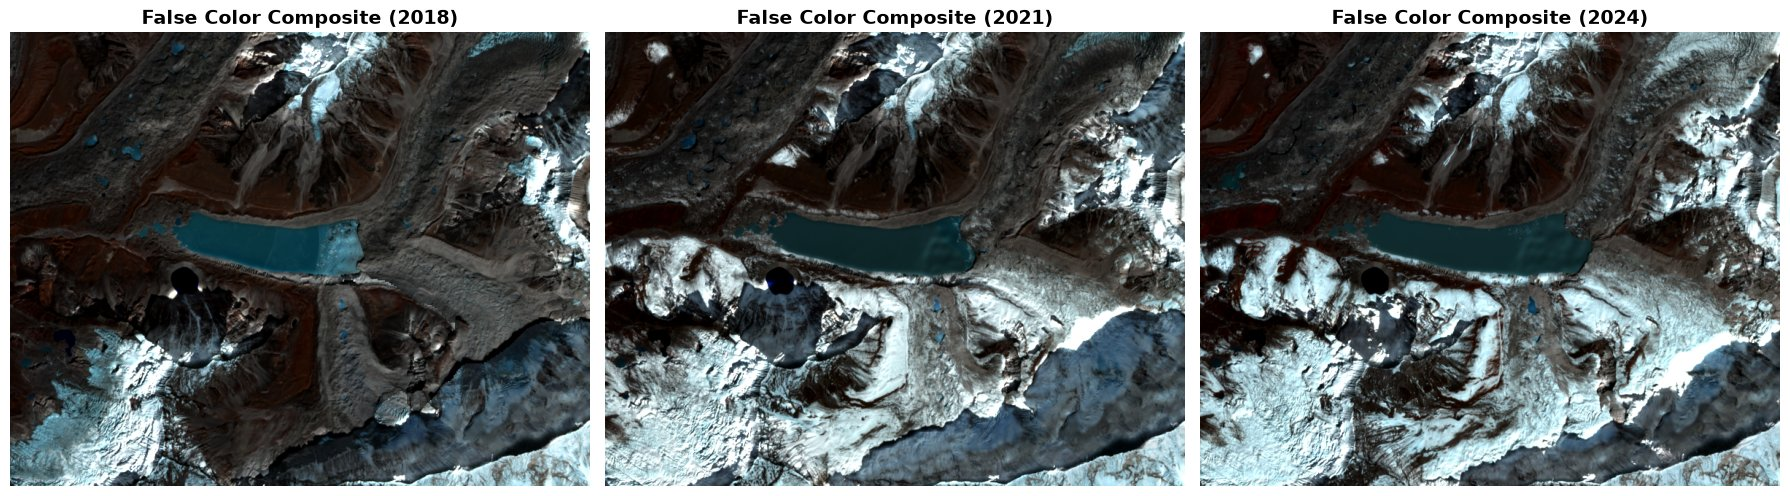

In [3]:
fig = plotting.plot_false_color_composites(scenes)

## 3. Spectral water indices

Both indices are normalised differences, bounded to [-1, 1].

**MNDWI, the primary detector.** `(Green − SWIR) / (Green + SWIR)` using B03 and B11 (Xu, 2006). Liquid water absorbs shortwave-infrared strongly regardless of how much sediment it carries, so MNDWI gives the turbid lake a strong, unambiguous signal.

**NDWI, a secondary filter.** `(Green − NIR) / (Green + NIR)` using B03 and B08 (McFeeters, 1996). Suspended sediment raises the lake's near-infrared reflectance and weakens its NDWI, which is why NDWI is not used as the primary detector here. It is still positive over the lake, so `NDWI > 0` is used as a confirmation test.

**The snow problem.** The MNDWI formula is identical to the Normalized Difference Snow Index (NDSI; Hall et al., 1995). Snow and ice therefore score as high on MNDWI as water does. What separates them is near-infrared brightness: water absorbs NIR, while snow and ice reflect it strongly. Pixels with B08 reflectance of `NIR_CEILING` (0.20) or more are therefore rejected. Without this test, the snowfields south of the lake merge with it into a single component several times the lake's size.

In [4]:
detections = {year: detect_lake(scene) for year, scene in scenes.items()}

for year, det in detections.items():
    lake = det.lake_mask
    nir = det.scene.bands["B08"]
    rejected = (det.mndwi > det.otsu_threshold) & (nir >= NIR_CEILING)
    print(
        f"{year}: lake median MNDWI {np.median(det.mndwi[lake]):.2f}, "
        f"NDWI {np.median(det.ndwi[lake]):.2f}, NIR {np.median(nir[lake]):.3f} | "
        f"above the MNDWI threshold but rejected as snow/ice: "
        f"{rejected.sum() * det.scene.pixel_area_m2 / 1e6:.1f} km²"
    )

2018: lake median MNDWI 0.93, NDWI 0.54, NIR 0.082 | above the MNDWI threshold but rejected as snow/ice: 10.0 km²
2021: lake median MNDWI 0.94, NDWI 0.28, NIR 0.122 | above the MNDWI threshold but rejected as snow/ice: 24.5 km²
2024: lake median MNDWI 0.97, NDWI 0.31, NIR 0.121 | above the MNDWI threshold but rejected as snow/ice: 23.7 km²


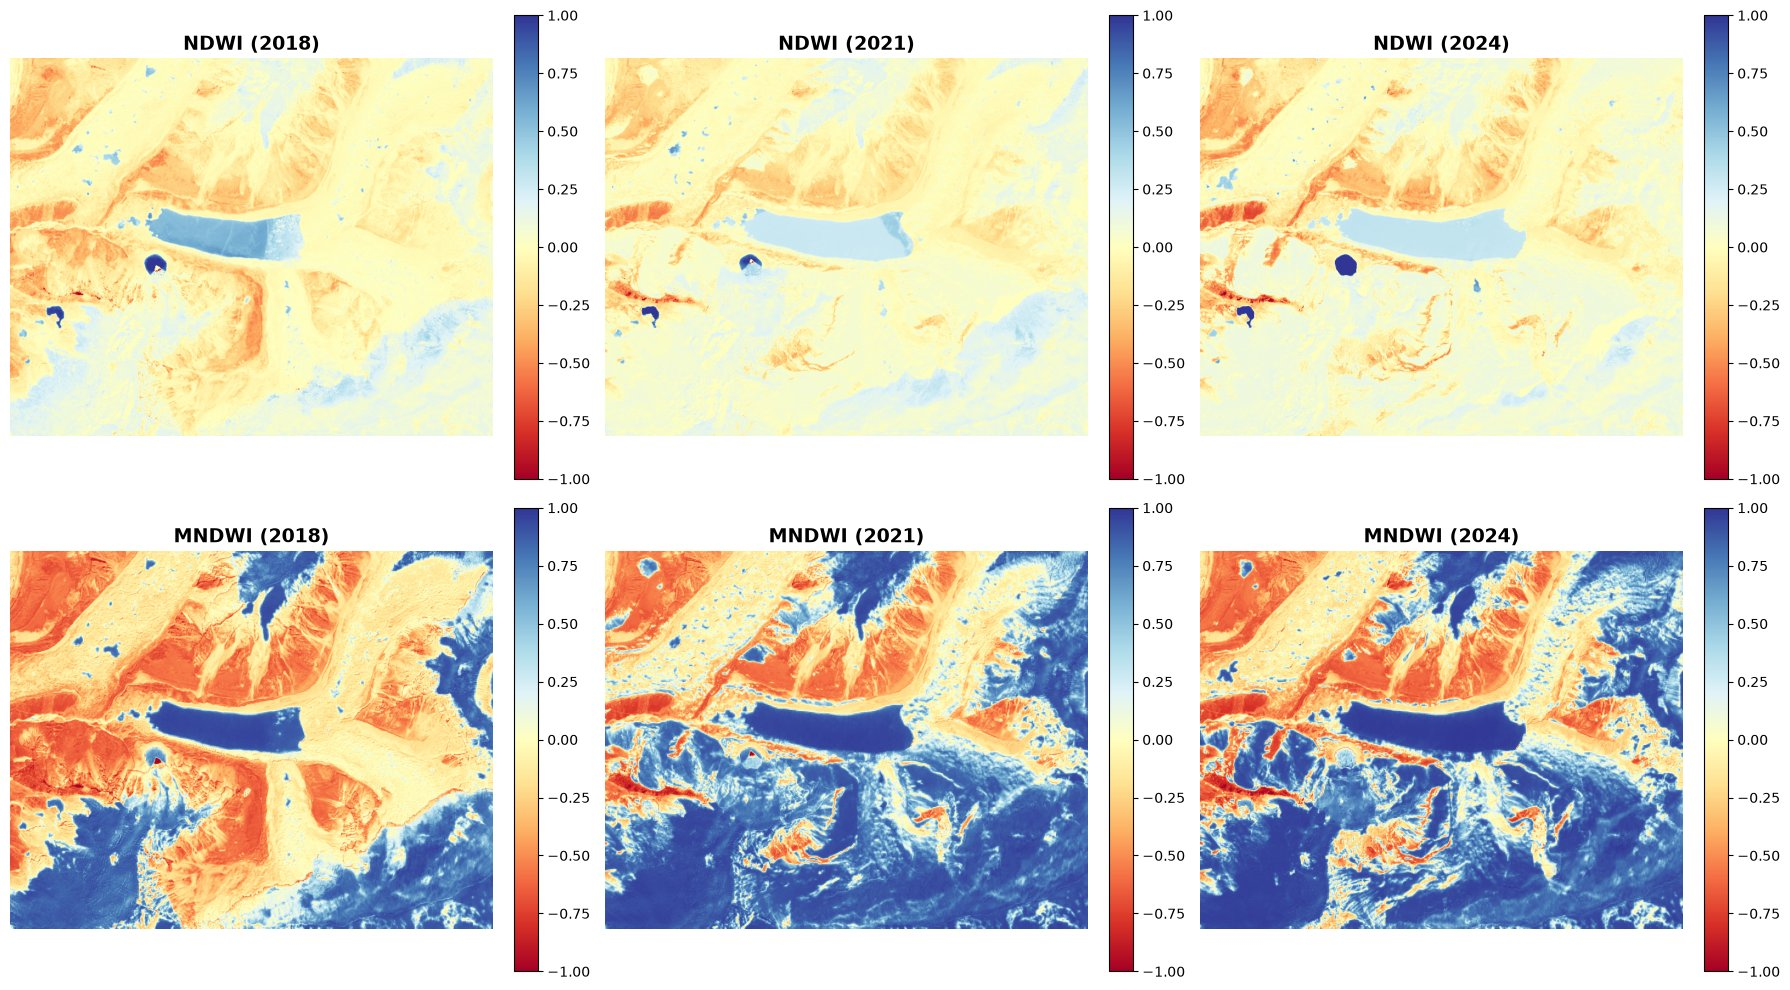

In [5]:
fig = plotting.plot_index_maps(detections)

### Why not threshold NDWI directly?

Otsu's method needs a bimodal distribution, with the threshold falling in the valley between two modes. The NDWI histograms below show that this condition is not met. The lake forms only a small, narrow peak (around 0.53 in 2018 and 0.27–0.31 in 2021 and 2024), dwarfed by the broad distribution of snow, ice and terrain around 0–0.1. The peak's position also shifts between dates, so no single NDWI threshold carries over from one year to the next. Otsu's method applied to NDWI lands near zero on every date (0.03, −0.02 and −0.10), which would classify most of the snow cover as water.

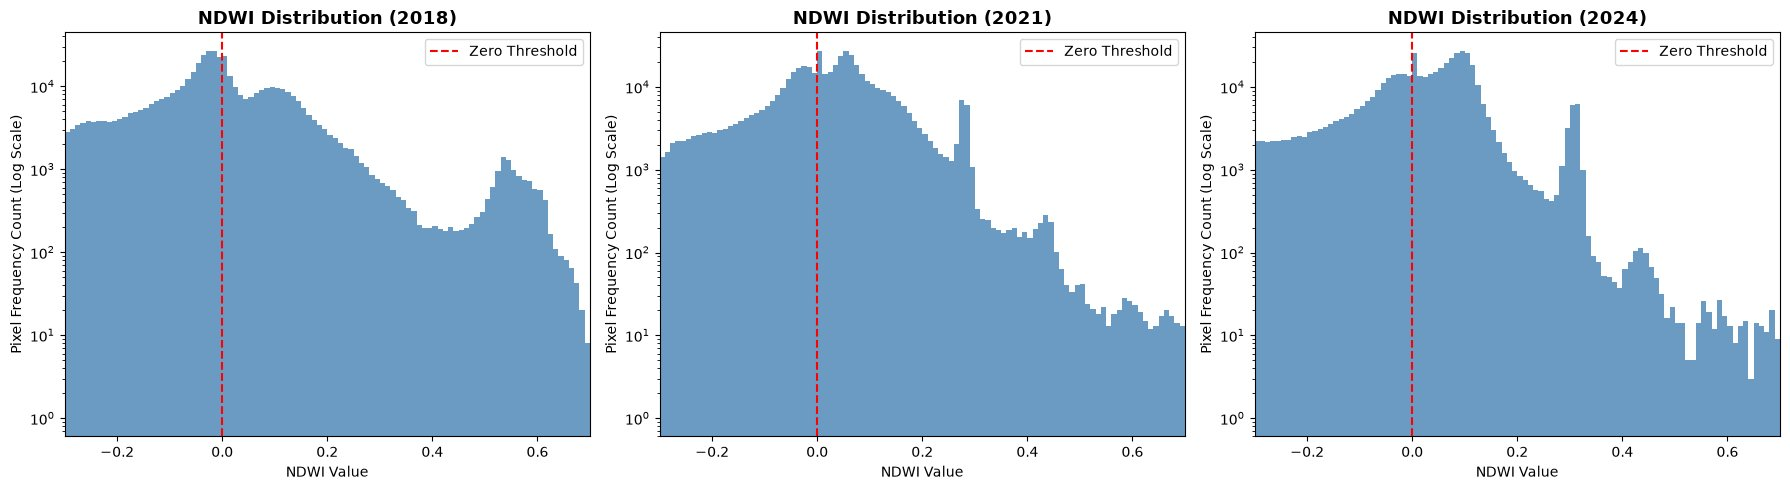

In [6]:
fig = plotting.plot_index_histograms(detections, "NDWI", xlim=(-0.3, 0.7))

## 4. Water segmentation and lake area

For each date the open-water mask is `MNDWI > Otsu threshold & NDWI > 0 & B08 < 0.20`. This mask still contains hundreds of small, disconnected water-like patches across the scene: shadowed snow, small ponds and wet ground. **Connected-component labelling** groups touching pixels (8-connectivity) into separate bodies, and only the largest one, Imja Tsho, is kept and measured.

In [7]:
areas = {year: det.area_km2 for year, det in detections.items()}

header = ("Year", "MNDWI Otsu", "Water px", "Components", "Lake px", "Area (km²)")
print(" | ".join(f"{h:>10}" for h in header))
print("-" * 70)
for year, det in detections.items():
    _, sizes = label_components(det.water_mask)
    row = (
        f"{year:>10}",
        f"{det.otsu_threshold:>10.4f}",
        f"{int(det.water_mask.sum()):>10}",
        f"{int(np.count_nonzero(sizes)):>10}",
        f"{int(det.lake_mask.sum()):>10}",
        f"{det.area_km2:>10.3f}",
    )
    print(" | ".join(row))

print()
for change in metrics.area_changes(areas):
    print(f"{change.start}–{change.end}: {change.absolute_km2:+.3f} km² ({change.percent:+.2f}%)")
print(f"Compound annual growth rate: {metrics.compound_annual_growth_rate(areas):.2%}")

      Year | MNDWI Otsu |   Water px | Components |    Lake px | Area (km²)
----------------------------------------------------------------------
      2018 |     0.2275 |      37861 |       1043 |      11785 |      1.179
      2021 |     0.2695 |      34261 |        980 |      15715 |      1.571
      2024 |     0.2517 |      31505 |        778 |      17921 |      1.792

2018–2021: +0.393 km² (+33.35%)
2021–2024: +0.221 km² (+14.04%)
2018–2024: +0.614 km² (+52.07%)
Compound annual growth rate: 7.24%


### Results overview

The grid places the true- and false-colour images next to the MNDWI map and the final lake mask. The green line on the MNDWI panels is the Otsu threshold contour. Many of the regions it encloses outside the lake are snow and ice, which pass the MNDWI threshold but are removed by the NIR test. The rest are small disconnected patches dropped by the largest-component step.

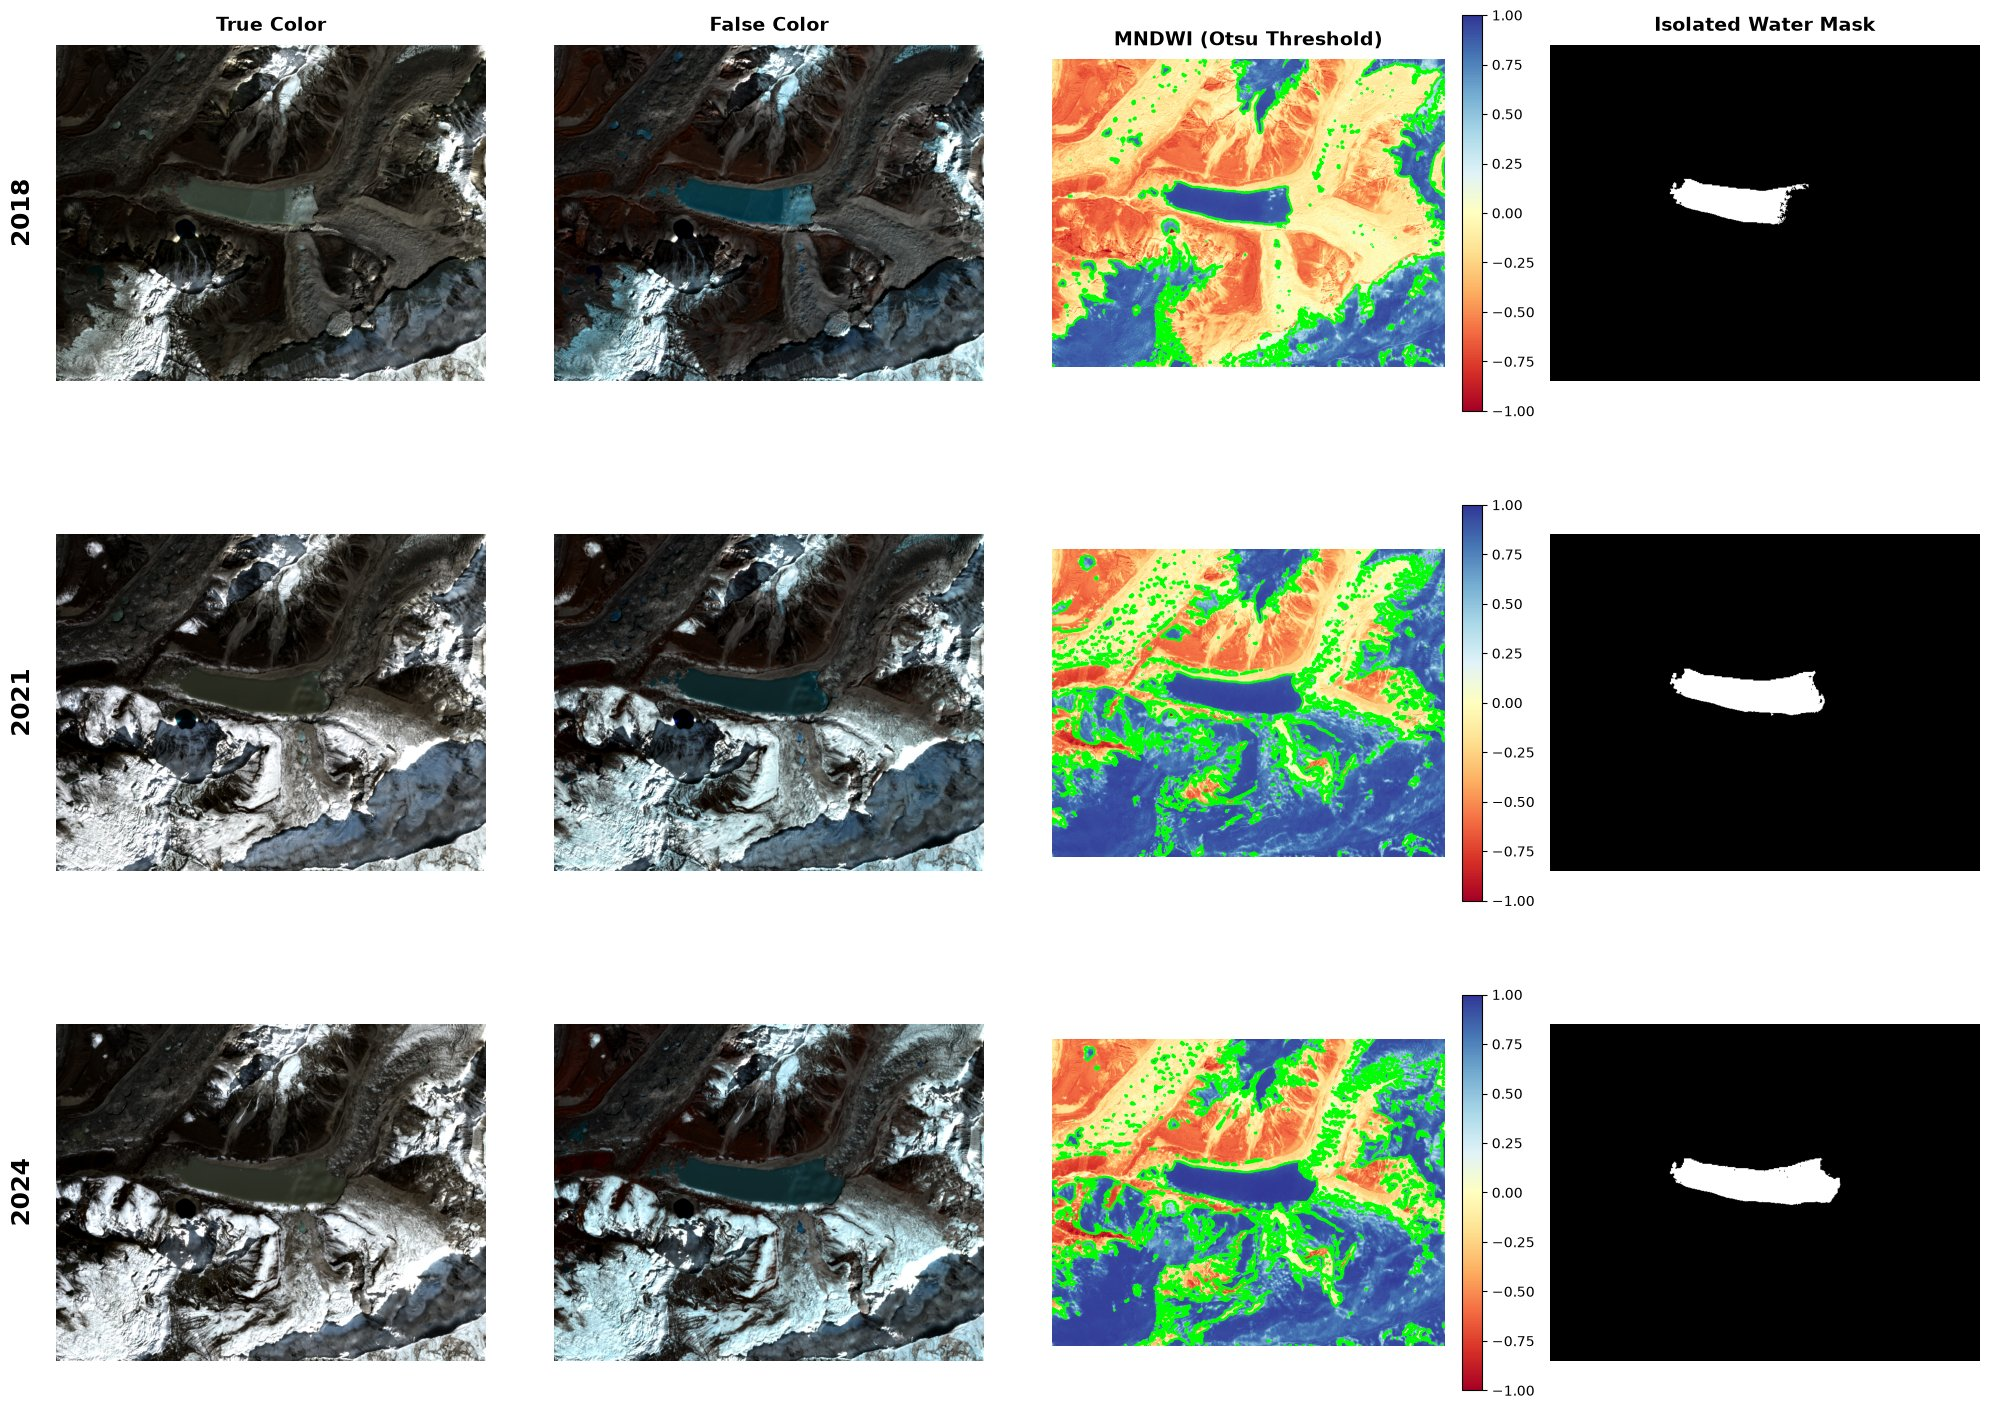

In [8]:
fig = plotting.plot_results_grid(detections)

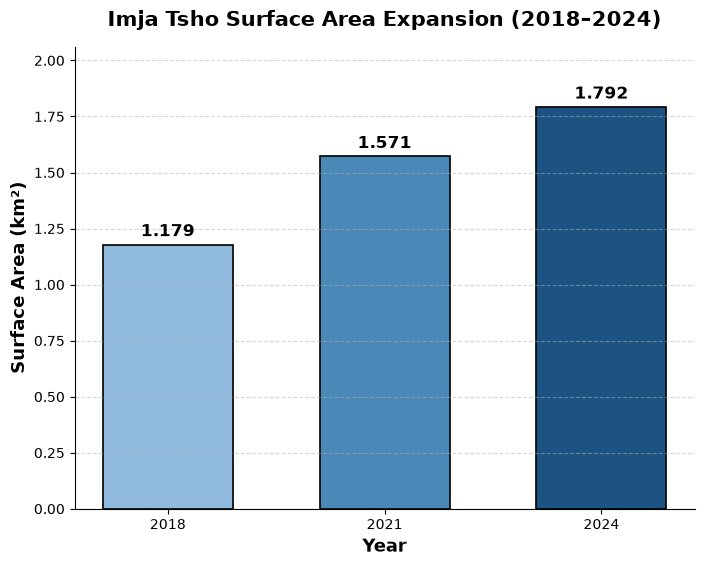

In [9]:
fig = plotting.plot_area_bars(areas)

### Checking the Otsu assumption on MNDWI

Unlike NDWI, the MNDWI histograms are clearly bimodal: a land mode around −0.15 and a high mode around 0.9. The Otsu threshold (0.23–0.27) falls in the valley between them on every date. The high mode contains both water and snow/ice, which is why Otsu's method alone is not enough and the NIR test from Section 3 is needed.

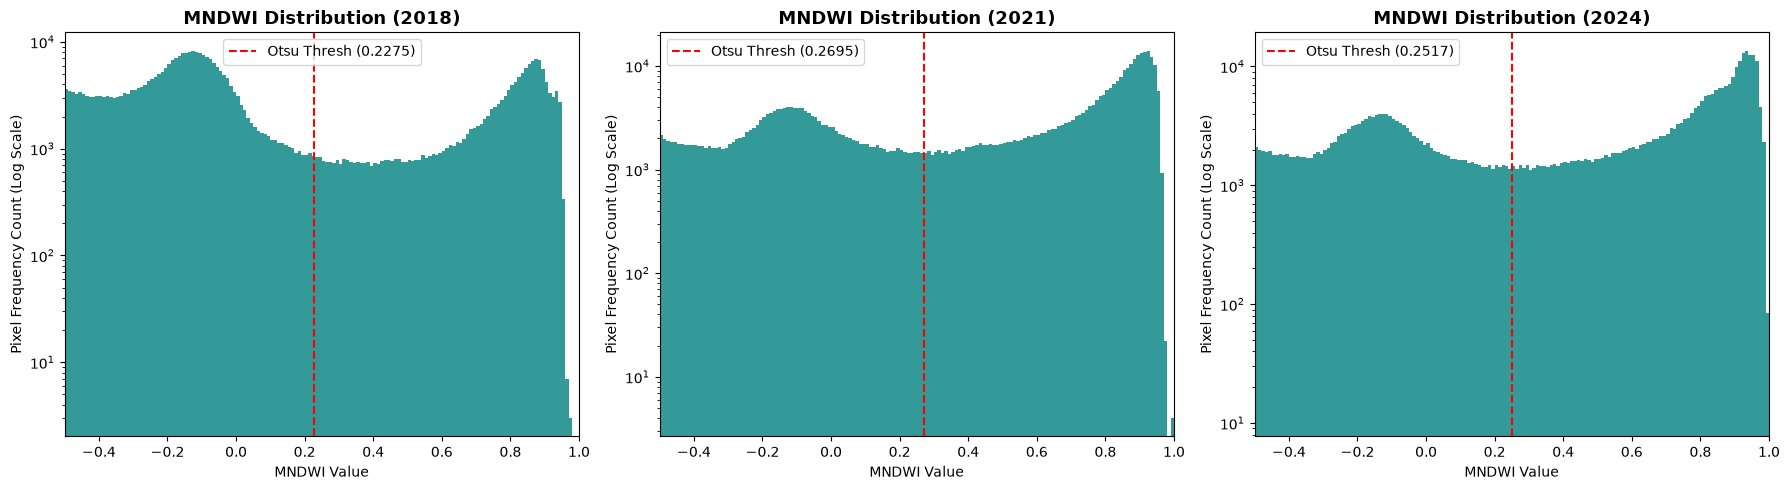

In [10]:
fig = plotting.plot_index_histograms(
    detections, "MNDWI", xlim=(-0.5, 1.0), show_otsu=True, color="teal"
)

## 5. Validation

### Is it the same lake every year?

Selecting "the largest component" could in principle pick a different object on different dates. Two checks rule this out:

- **Nesting.** If the lake only grows, nearly all of each earlier outline should lie inside the later one.
- **Shoreline positions.** Imja Tsho is dammed by a terminal moraine at its western end and grows eastward as Imja Glacier retreats. The western shore should stay fixed while the eastern shore advances.

Because the growth happens at one end, the centroid is *expected* to move east by up to a few hundred metres. A centroid-stability test would wrongly flag this as an error.

In [11]:
shapes = {
    year: metrics.shape_descriptors(det.lake_mask, det.scene.pixel_size_m)
    for year, det in detections.items()
}
pixel_width = scenes[target_years[0]].pixel_size_m[0]

print("Shoreline extent (column of westernmost / easternmost lake pixel):")
for year, shape in shapes.items():
    west, east = shape.col_range
    print(
        f"  {year}: west {west}, east {east} -> length {(east - west + 1) * pixel_width:.0f} m, "
        f"aspect ratio {shape.aspect_ratio:.2f}"
    )

print("\nNesting (share of the earlier lake inside the later lake):")
consecutive = list(zip(target_years, target_years[1:], strict=False))
for earlier, later in [*consecutive, (target_years[0], target_years[-1])]:
    share = metrics.containment(detections[earlier].lake_mask, detections[later].lake_mask)
    print(f"  {earlier} inside {later}: {share:.1%}")

print("\nEastern shoreline advance:")
for earlier, later in consecutive:
    advance = (shapes[later].col_range[1] - shapes[earlier].col_range[1]) * pixel_width
    print(f"  {earlier}–{later}: {advance:+.0f} m")

Shoreline extent (column of westernmost / easternmost lake pixel):
  2018: west 222, east 477 -> length 2560 m, aspect ratio 3.05
  2021: west 222, east 507 -> length 2860 m, aspect ratio 3.29
  2024: west 222, east 536 -> length 3150 m, aspect ratio 3.62

Nesting (share of the earlier lake inside the later lake):
  2018 inside 2021: 96.7%
  2021 inside 2024: 99.6%
  2018 inside 2024: 98.2%

Eastern shoreline advance:
  2018–2021: +300 m
  2021–2024: +290 m


The western shore sits on the same pixel column on all three dates, while the eastern shore advances by about 300 m in each interval. Over 96% of each earlier outline lies within the later one. The algorithm tracked the same lake throughout, and the lake grew at its glacier end.

### Shoreline evolution

Overlaying the three outlines on the 2024 true-colour image shows the same pattern, and the zoomed view shows how closely the mask follows the visible shoreline.

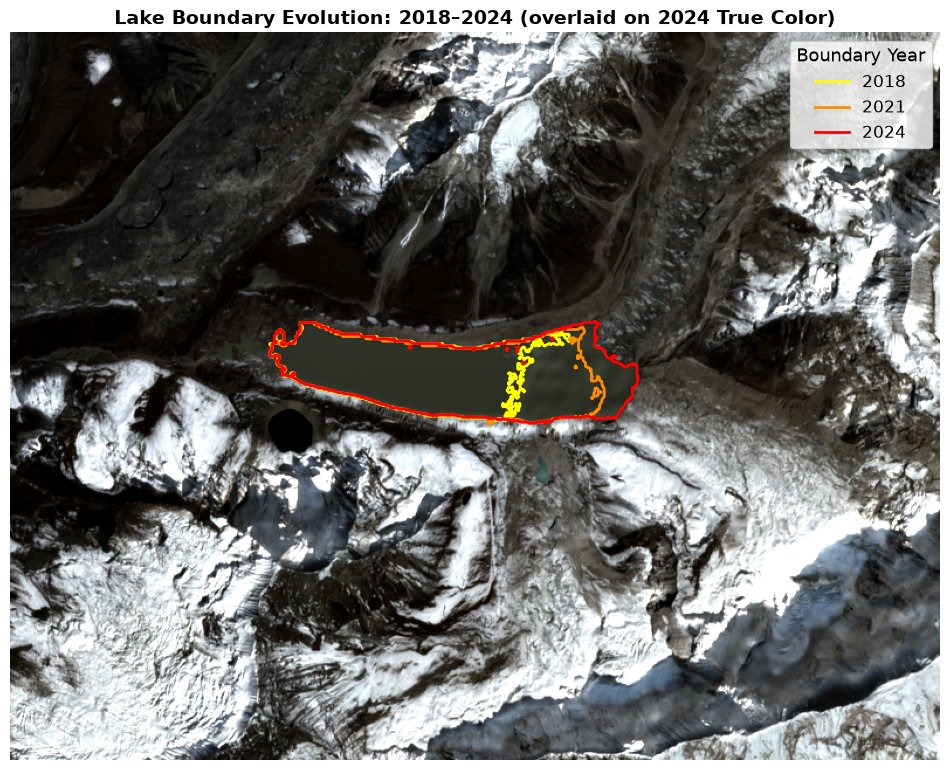

In [12]:
fig = plotting.plot_boundary_evolution(detections)

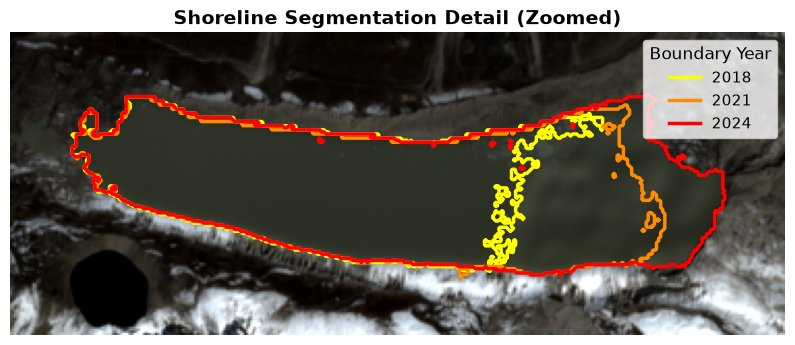

In [13]:
fig = plotting.plot_boundary_evolution(detections, zoom_padding=30)

### Was the lake split into pieces?

If floating ice or a shadow had cut the lake into separate bodies on some date, the largest-component step would keep only one piece and underestimate the area. The test is therefore not "are there other large components?" There always are, mostly snow and shadow patches far from the lake. The question is whether any sizeable water component lies **right next to** the lake. The cell below lists every other component within 30 m of the lake outline.

In [14]:
NEAR_DISTANCE_PX = 3  # 30 m

for year, det in detections.items():
    nearby = metrics.nearby_component_sizes(det.water_mask, det.lake_mask, NEAR_DISTANCE_PX)
    nearby_km2 = nearby * det.scene.pixel_area_m2 / 1e6
    largest = nearby_km2[0] if nearby.size else 0.0
    print(
        f"{year}: {nearby.size} components within {NEAR_DISTANCE_PX * pixel_width:.0f} m, "
        f"total {nearby_km2.sum():.4f} km², largest {largest:.4f} km² "
        f"({largest / det.area_km2:.2%} of the lake)"
    )

2018: 10 components within 30 m, total 0.0136 km², largest 0.0058 km² (0.49% of the lake)
2021: 7 components within 30 m, total 0.0028 km², largest 0.0008 km² (0.05% of the lake)
2024: 6 components within 30 m, total 0.0007 km², largest 0.0002 km² (0.01% of the lake)


The components bordering the lake are tiny: at most a few thousandths of a km², well under 1% of the lake area. The lake was not fragmented on any date. The figure below shows the pre-isolation masks for 2018 and 2021. The second- and third-largest components are snow and shadow patches in the south of the scene, kilometres from the lake.

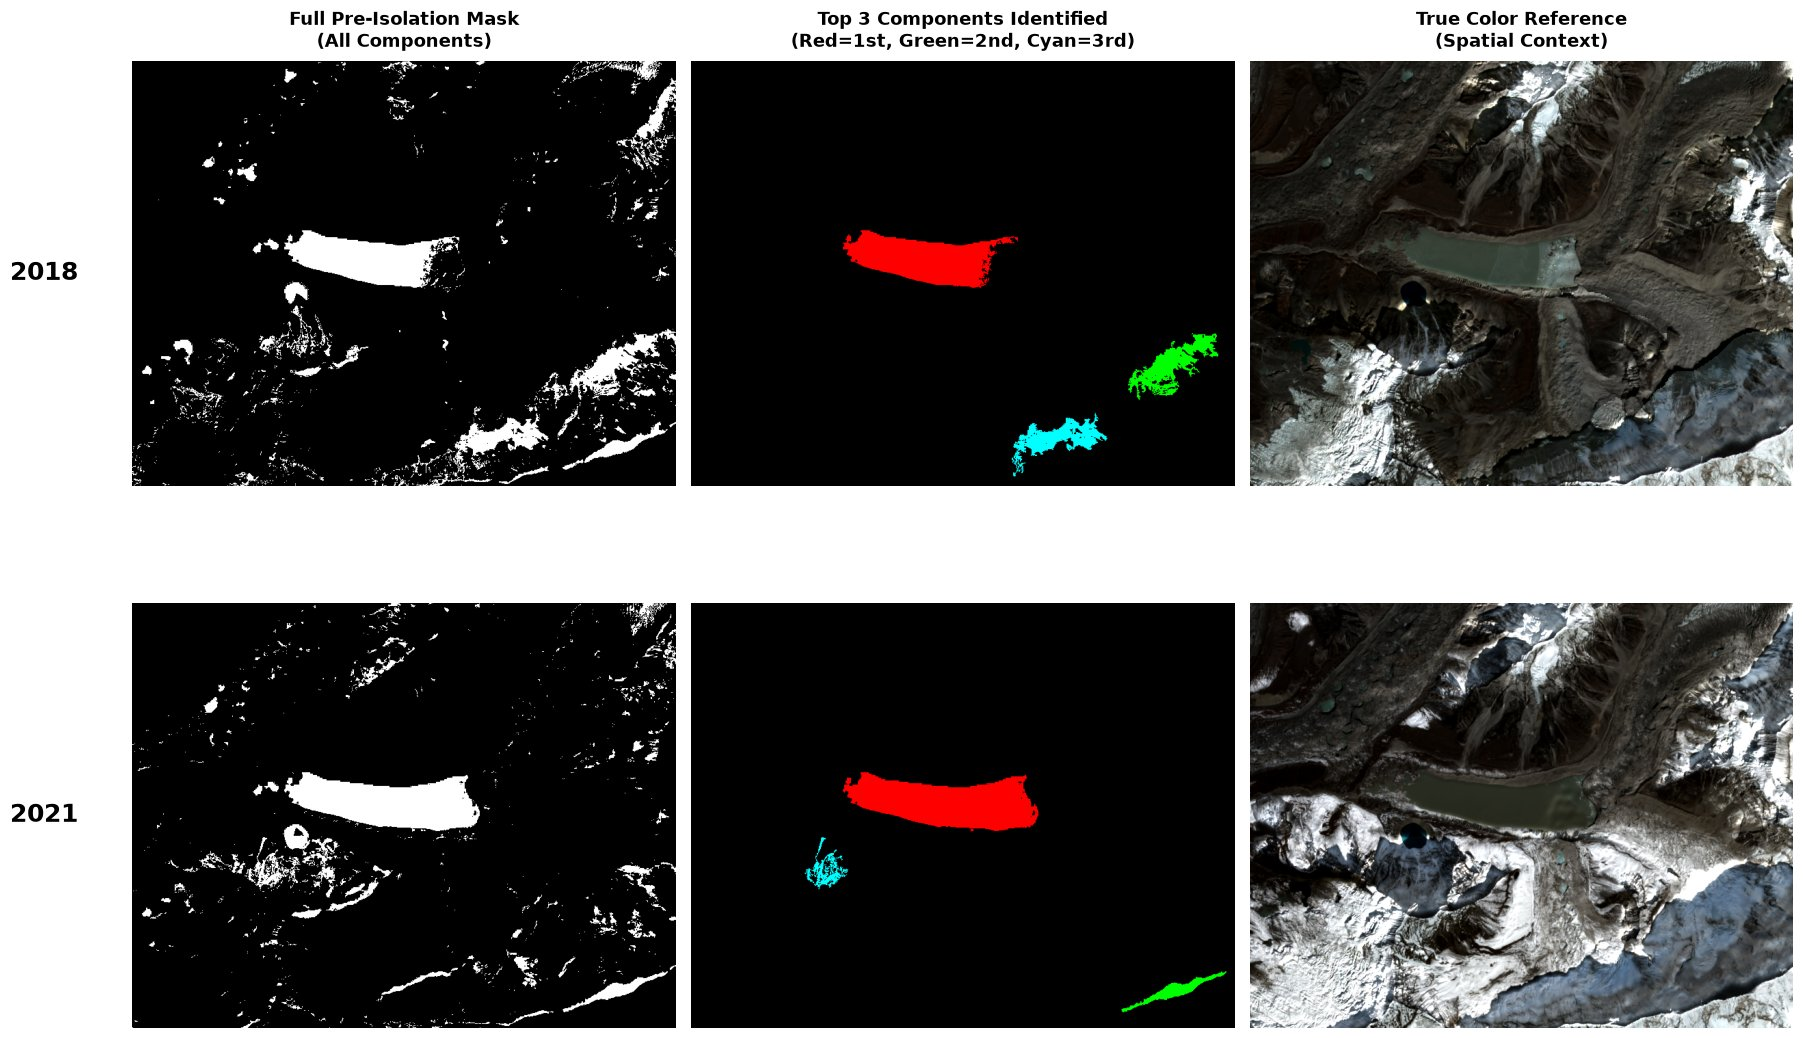

In [15]:
fig = plotting.plot_fragmentation({year: detections[year] for year in target_years[:2]})

### Boundary uncertainty

At 10 m resolution, pixels along the shoreline are mixtures of water and land, and any of them could be misclassified. Counting one pixel (100 m²) of uncertainty per point on the outline gives a conservative bound on each measurement.

In [16]:
for year, det in detections.items():
    n_boundary = metrics.boundary_length_px(det.lake_mask)
    uncertainty = metrics.boundary_uncertainty_km2(det.lake_mask, det.scene.pixel_area_m2)
    print(f"{year}: {det.area_km2:.3f} ± {uncertainty:.3f} km² ({n_boundary} boundary pixels)")

2018: 1.179 ± 0.118 km² (1180 boundary pixels)
2021: 1.571 ± 0.098 km² (983 boundary pixels)
2024: 1.792 ± 0.104 km² (1040 boundary pixels)


## 6. Conclusions

### Findings

The open-water area of Imja Tsho was **1.179 km²** on 30 October 2018, **1.571 km²** on 8 November 2021 and **1.792 km²** on 13 October 2024. That is a growth of 0.393 km² (+33.4%) between 2018 and 2021 and 0.221 km² (+14.0%) between 2021 and 2024: **0.614 km² (+52.1%) overall**, or a compound annual growth rate of about 7.2%. The total change is several times larger than the boundary uncertainty of each measurement (±0.10–0.12 km²).

The growth is entirely at the eastern, glacier end of the lake. The moraine-dammed western shore did not move, while the eastern shore advanced by about 300 m in each three-year interval, consistent with the glacier front retreating as it loses ice into the lake.

### Open water versus total lake area

On the 2018 image, the eastern end of the lake, next to the glacier front, is covered by bright ice. The NIR test correctly excludes it, because it is not open water, but this means the 2018 figure underestimates the full lake basin. Part of the 2018–2021 increase therefore reflects ice clearing rather than new lake area, and the two effects cannot be separated from these three images. The reported values should be read as *open-water area at the time of acquisition*. The 2021–2024 change, with little ice on either date, is the cleaner estimate of true expansion.

### Method notes

- **Snow rejection.** MNDWI cannot tell water from snow, because it uses the same formula as the snow index NDSI. A near-infrared reflectance ceiling (B08 < 0.20) separates them, because liquid water absorbs NIR. The value is empirical: a stricter 0.15 starts to cut into the sediment plumes in the lake, whose NIR reflectance is around 0.12–0.15.
- **Connected components.** Even after snow rejection, the water mask contains hundreds of small separate patches. Keeping the largest connected component isolates the lake reliably, and the nesting and fragmentation checks confirm that it is the same, intact lake on every date.

### Limitations

- **Per-date thresholds.** The Otsu threshold is computed separately for each date (0.23–0.27). Some year-to-year variation may come from threshold changes rather than the lake; a single threshold pooled over all dates would be a useful robustness check.
- **Fixed NIR ceiling.** The 0.20 ceiling is a single empirical value. Lake water with very high sediment content, or thin ice and slush, could fall on either side of it.
- **Season.** The acquisitions span mid-October to early November, so the extent of lake ice and snow differs between dates, most visibly in 2018.
- **Shadows.** Steep terrain casts deep shadows in which all reflectances approach zero and the normalised-difference indices become unstable. These pixels can show extreme index values, but they lie away from the lake and are removed by the largest-component step.
- **Resolution.** At 10 m, shoreline pixels are mixed. The boundary uncertainty above is a deliberately conservative bound.

### Relevance for GLOF hazard

A larger lake behind the same moraine dam means more water that could be released in an outburst flood. The roughly 7% per year growth in open-water area measured here, concentrated at the glacier end, is consistent with continued glacier retreat into the lake. The pipeline is automatic apart from the choice of dates, so applying it to more frequent acquisitions would give a monitoring record of the expansion rate itself.

## References

- Hall, D. K., Riggs, G. A., & Salomonson, V. V. (1995). Development of methods for mapping global snow cover using moderate resolution imaging spectroradiometer data. *Remote Sensing of Environment*, 54(2), 127–140.
- McFeeters, S. K. (1996). The use of the Normalized Difference Water Index (NDWI) in the delineation of open water features. *International Journal of Remote Sensing*, 17(7), 1425–1432.
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Transactions on Systems, Man, and Cybernetics*, 9(1), 62–66.
- Xu, H. (2006). Modification of normalised difference water index (NDWI) to enhance open water features in remotely sensed imagery. *International Journal of Remote Sensing*, 27(14), 3025–3033.
- Contains modified Copernicus Sentinel data (2018, 2021, 2024), processed by the Copernicus Data Space Ecosystem.